# 02 · EDA Bagian 1 — Aplikasi & Profil Nasabah

**Sumber data**: `train_applications` + `customer_profiles` (+ satu tabel kecil `account_behavior` khusus untuk Q6).

| # | Pertanyaan |
|---|---|
| Q1 | Apakah ada pola **waktu** (bulan, hari, jam, lama proses) terhadap target? |
| Q2 | Dari semua kolom aplikasi & profil, mana yang **benar-benar** punya sinyal? |
| Q3 | Seberapa kuat **suku bunga**, dan apa yang menentukannya? |
| Q4 | Bagaimana **karakteristik pinjaman** (nominal, cicilan, tujuan) berhubungan dengan risiko? |
| Q5 | Bagaimana **profil nasabah** (umur, pekerjaan, pendapatan, tanggungan, rumah, wilayah) berhubungan dengan risiko? |
| Q6 | Apakah **pendapatan deklarasi** bisa dipercaya, dan apakah *affordability* (DTI) prediktif? |
| Q7 | Setelah suku bunga diketahui, apakah fitur lain masih menambah informasi? |
| Q8 | Apa beda **nasabah baru vs nasabah lama**? |
| Q9 | Berapa KS yang bisa dicapai hanya dengan aplikasi + profil? (*patokan untuk bagian selanjutnya*) |

**Cara membaca grafik target rate** (dipakai di semua notebook EDA):
- Garis biru = % target=1 per bin, pita = interval kepercayaan 95%. Garis putus-putus abu = rata-rata keseluruhan (13,58%).
- Panel bawah = porsi baris di tiap bin. Kotak oranye (jika ada) = baris dengan nilai null.
- **KS di judul** = KS fitur itu sendirian. Bandingkan dengan **noise floor** di Q2.

> Semua analisis target hanya memakai **train**.

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import eda_utils as E

E.setup_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

tr = E.load("train_applications")
cp = E.load("customer_profiles")
has_hist = E.load("previous_applications", ["customer_id"]).unique().with_columns(has_history=pl.lit(True))

df = (
    tr.join(cp, on="customer_id", how="left")
      .join(has_hist, on="customer_id", how="left")
      .with_columns(
          pl.col("has_history").fill_null(False),
          # --- waktu
          dec_month=pl.col("decision_datetime").dt.month(),
          dec_day=pl.col("decision_datetime").dt.day(),
          dec_weekday=pl.col("decision_datetime").dt.weekday(),          # 1 = Senin
          dec_hour=pl.col("decision_datetime").dt.hour(),
          app_hour=pl.col("application_datetime").dt.hour(),
          lag_hours=(pl.col("decision_datetime") - pl.col("application_datetime")).dt.total_seconds() / 3600,
          # --- affordability (pendapatan DEKLARASI)
          dti=pl.col("proposed_monthly_installment") / pl.col("declared_monthly_income"),
          lti=pl.col("loan_amount") / (pl.col("declared_monthly_income") * 12),
          income_per_capita=pl.col("declared_monthly_income") / (1 + pl.col("dependents")),
          residual_income=pl.col("declared_monthly_income") - pl.col("proposed_monthly_installment"),
          tenure_share_of_career=pl.col("employment_tenure_months") / ((pl.col("age") - 18).clip(1) * 12),
      )
)
y = df["target"].to_numpy()
BASE = y.mean()
print(f"{df.height:,} baris train | target rate {BASE:.2%}")

70,000 baris train | target rate 13.58%


## Q1 · Apakah ada pola waktu?

Kalau risiko berubah menurut bulan/hari/jam, fitur kalender bisa berguna. Tapi karena train dan test diambil **acak dari periode yang sama**, fitur waktu juga mudah membuat model *menghafal noise*. Jadi kita perlu bukti yang jelas sebelum memakainya.

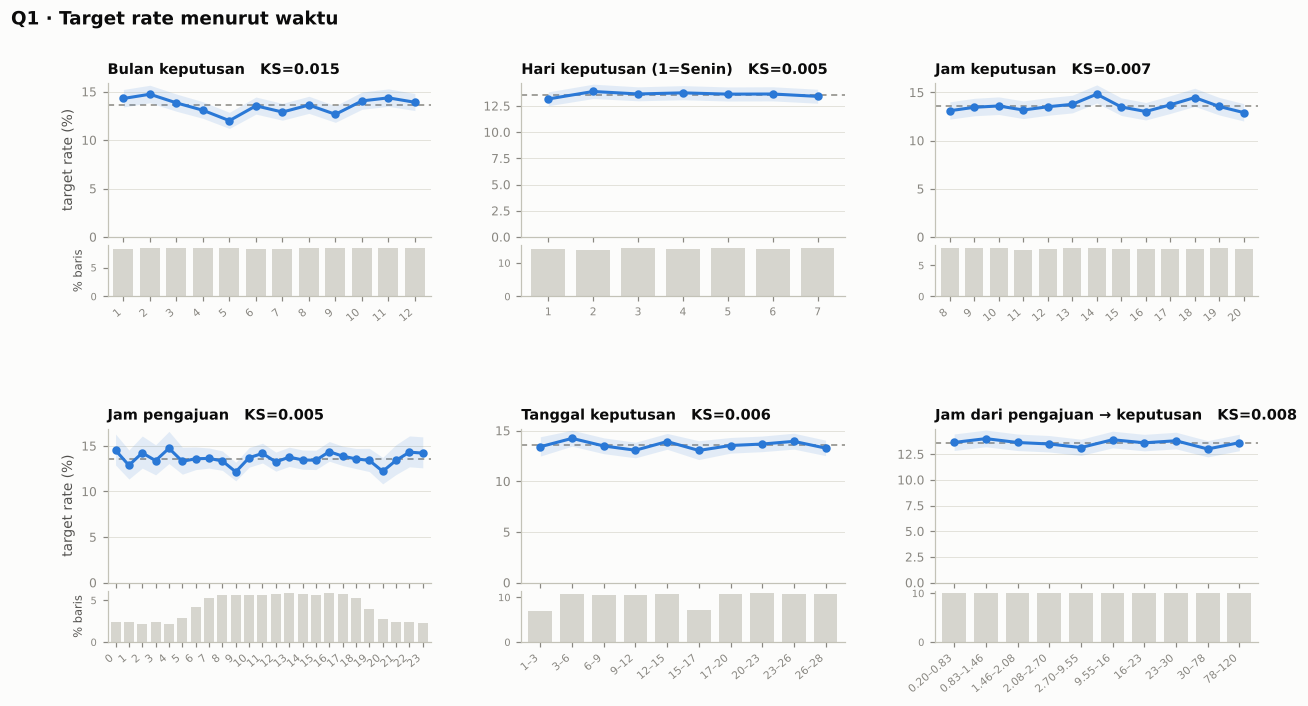

In [2]:
E.plot_rates(df, ["dec_month", "dec_weekday", "dec_hour", "app_hour", "dec_day", "lag_hours"],
             titles={"dec_month": "Bulan keputusan", "dec_weekday": "Hari keputusan (1=Senin)",
                     "dec_hour": "Jam keputusan", "app_hour": "Jam pengajuan",
                     "dec_day": "Tanggal keputusan", "lag_hours": "Jam dari pengajuan → keputusan"},
             bins=10, suptitle="Q1 · Target rate menurut waktu")

## Q2 · Peta sinyal: kolom mana yang benar-benar informatif?

**Noise floor**: dengan 70.000 baris (9.507 positif), bahkan fitur yang 100% acak pun akan menghasilkan KS > 0. Kita hitung berapa KS yang bisa muncul **murni karena kebetulan** dengan 200 fitur acak. Fitur yang KS-nya tidak melewati angka ini praktis tidak bisa dibedakan dari noise.

Aturan baca: **> 2× noise = jelas**, **1,5–2× = tipis**, **< 1,5× = noise**. Batas 1,5× dipakai karena kita menguji ~23 kolom sekaligus, sehingga 1–2 kolom acak bisa "lolos" persentil-95 secara kebetulan.
Untuk kolom kategori, KS dihitung setelah kategori diurutkan menurut bad rate-nya, jadi sedikit optimistis.

In [3]:
NOISE = E.ks_noise_floor(y, n_perm=200, q=0.95)
print(f"Noise floor KS (persentil 95 dari 200 fitur acak): {NOISE:.4f}")

CANDIDATES = [
    "annual_interest_rate", "loan_amount", "proposed_monthly_installment", "loan_purpose",
    "age", "region", "employment_type", "employment_tenure_months", "declared_monthly_income",
    "dependents", "housing_status", "has_history",
    "dti", "lti", "income_per_capita", "residual_income", "tenure_share_of_career",
    "dec_month", "dec_weekday", "dec_hour", "app_hour", "dec_day", "lag_hours",
]
sig = E.signal_table(df, CANDIDATES).with_columns(
    (pl.col("ks") / NOISE).round(1).alias("ks_x_noise"),
    pl.when(pl.col("ks") > 2 * NOISE).then(pl.lit("✅ jelas"))
      .when(pl.col("ks") > 1.5 * NOISE).then(pl.lit("⚠️ tipis"))
      .otherwise(pl.lit("— noise")).alias("verdict"),
)
sig

Noise floor KS (persentil 95 dari 200 fitur acak): 0.0144


feature,type,null_pct,n_unique,ks,auc,arah,iv,ks_x_noise,verdict
str,str,f64,i64,f64,f64,str,f64,f64,str
"""annual_interest_rate""","""num""",0.0,5,0.2301,0.6464,"""↑ nilai → ↑ risiko""",0.3201,16.0,"""✅ jelas"""
"""dti""","""num""",0.0,70000,0.0778,0.5498,"""↑ nilai → ↑ risiko""",0.0301,5.4,"""✅ jelas"""
"""lti""","""num""",0.0,69993,0.0684,0.5432,"""↑ nilai → ↑ risiko""",0.0227,4.7,"""✅ jelas"""
"""proposed_monthly_installment""","""num""",0.0,4041,0.0613,0.5412,"""↑ nilai → ↑ risiko""",0.0219,4.3,"""✅ jelas"""
"""loan_amount""","""num""",0.0,1270,0.0556,0.5373,"""↑ nilai → ↑ risiko""",0.018,3.9,"""✅ jelas"""
"""has_history""","""cat""",0.0,2,0.0476,0.5238,"""↑ nilai → ↑ risiko""",0.0112,3.3,"""✅ jelas"""
"""income_per_capita""","""num""",0.0,69940,0.0288,0.5175,"""↑ nilai → ↑ risiko""",0.004,2.0,"""⚠️ tipis"""
"""declared_monthly_income""","""num""",0.0,69871,0.0236,0.5145,"""↑ nilai → ↑ risiko""",0.0037,1.6,"""⚠️ tipis"""
"""dec_month""","""num""",0.0,12,0.0151,0.4988,"""↑ nilai → ↓ risiko""",0.0042,1.0,"""— noise"""


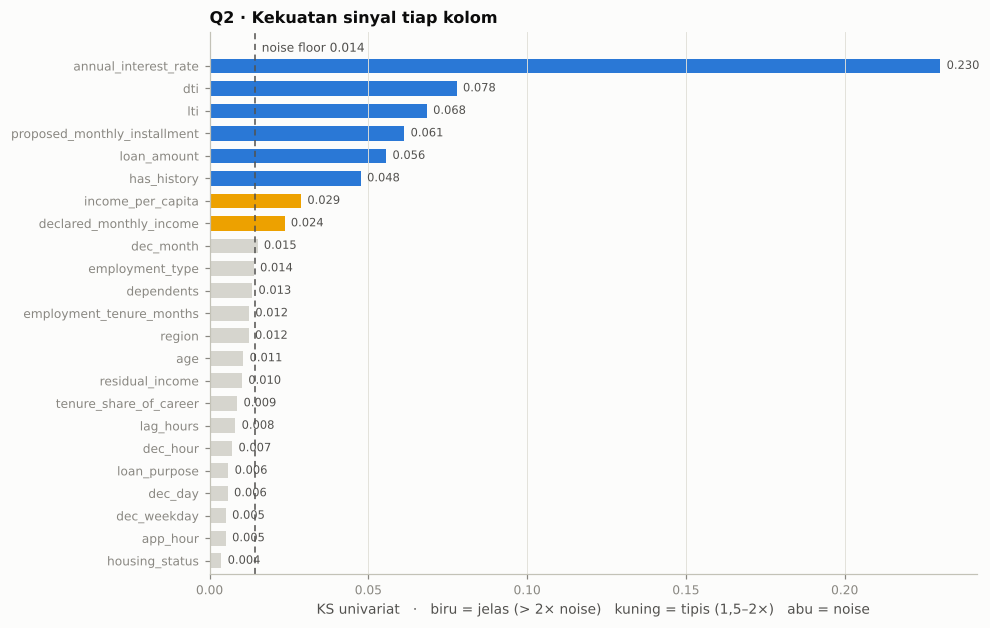

In [4]:
fig, ax = plt.subplots(figsize=(9, 6.4))
s = sig.sort("ks")
colors = [E.C_RATE if v.startswith("✅") else (E.SERIES[3] if v.startswith("⚠") else E.C_COUNT) for v in s["verdict"]]
ax.barh(s["feature"].to_list(), s["ks"].to_list(), color=colors, height=0.65)
ax.set_ylim(-0.6, len(s) + 0.5)
ax.axvline(NOISE, color=E.INK2, lw=1, ls=(0, (4, 3)))
ax.text(NOISE + 0.002, len(s) - 0.5, f"noise floor {NOISE:.3f}", fontsize=8, color=E.INK2, va="bottom")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("KS univariat   ·   biru = jelas (> 2× noise)   kuning = tipis (1,5–2×)   abu = noise")
ax.set_title("Q2 · Kekuatan sinyal tiap kolom")
for i, v in enumerate(s["ks"].to_list()):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=7.5, color=E.INK2)
plt.show()

**Jawaban Q2 — hanya satu kolom yang benar-benar kuat, yaitu suku bunga (KS 0,23).**
- **Tier 1**: `annual_interest_rate` (KS 0,23, IV 0,32), sekitar 16× noise floor.
- **Tier 2 (lemah tapi nyata)**: semua turunan beban pinjaman, yaitu `dti` 0,078, `lti` 0,068, `proposed_monthly_installment` 0,061, `loan_amount` 0,056, dan penanda `has_history` 0,048.
- **Tier 3 (tipis)**: `income_per_capita` (0,029) dan `declared_monthly_income` (0,024), hanya 1,6–2× noise.
- **Noise**: hampir seluruh **profil nasabah**. Umur, wilayah, jenis pekerjaan, masa kerja, tanggungan, status rumah, serta semua fitur waktu dan tujuan pinjaman punya KS 0,004–0,015, di bawah 1,5× noise floor.

Ini temuan penting: **data demografi hampir tidak membedakan nasabah macet dan lancar** di dataset ini. Sinyal harus dicari di tabel perilaku (riwayat bayar, biro, rekening, e-commerce).

## Q3 · Seberapa kuat suku bunga, dan apa yang menentukannya?

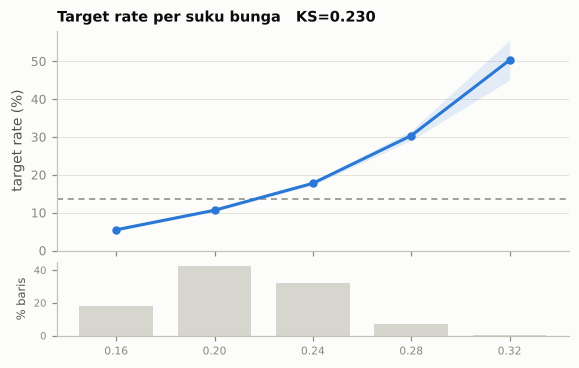

annual_interest_rate,n,target_rate,median_income,mean_age,median_loan,median_dti,pct_has_history,pct_salaried,pct_owned_house
f64,u32,f64,f64,f64,f64,f64,f64,f64,f64
0.16,12560,0.055,7826619.5,41.568,1.74e7,0.204,68.71,47.946,28.217
0.2,29800,0.106,7831701.5,41.372,1.87e7,0.228,68.584,47.886,28.027
0.24,22358,0.178,7.735258e6,41.536,1.99e7,0.251,70.959,47.849,27.489
0.28,4938,0.304,7.652262e6,41.466,2.11e7,0.273,76.488,47.408,27.683
0.32,344,0.503,7662774.5,40.555,2.09e7,0.292,84.302,41.279,26.453


In [5]:
E.plot_rates(df, ["annual_interest_rate"], ncols=1, width=6, row_h=3.6,
             titles={"annual_interest_rate": "Target rate per suku bunga"})
(df.group_by("annual_interest_rate")
   .agg(n=pl.len(), target_rate=pl.col("target").mean(),
        median_income=pl.col("declared_monthly_income").median(), mean_age=pl.col("age").mean(),
        median_loan=pl.col("loan_amount").median(), median_dti=pl.col("dti").median(),
        pct_has_history=pl.col("has_history").mean() * 100,
        pct_salaried=(pl.col("employment_type") == "salaried").mean() * 100,
        pct_owned_house=(pl.col("housing_status") == "owned").mean() * 100)
   .sort("annual_interest_rate")
   .with_columns(pl.col(pl.Float64).round(3)))

Bunga naik → default naik secara **monoton dan tajam** (5,5% → 10,6% → 17,8% → 30,4% → 50,3%). Tapi profil nasabah di setiap kelompok bunga **hampir identik**: pendapatan, umur, porsi karyawan tetap, dan porsi pemilik rumah praktis sama. Artinya lender **tidak** menentukan bunga dari profil. Yang sedikit naik bersama bunga hanya nominal pinjaman, DTI, dan porsi nasabah lama.

Dugaan kuat: bunga ditetapkan dari **skor biro dan/atau riwayat bayar**. Ini akan kita uji di Bagian 2 dan 3.

**⚠️ Jebakan redundansi**: cicilan adalah fungsi pasti dari (nominal, bunga, tenor 12). Jadi rasio `cicilan / nominal` **membocorkan suku bunga 100%**:

In [6]:
(df.with_columns(installment_per_million=pl.col("proposed_monthly_installment") / pl.col("loan_amount") * 1e6)
   .group_by("annual_interest_rate")
   .agg(min=pl.col("installment_per_million").min(), max=pl.col("installment_per_million").max())
   .sort("annual_interest_rate"))

annual_interest_rate,min,max
f64,f64,f64
0.16,90730.857875,90731.666667
0.2,92634.5059,92635.0
0.24,94559.596639,94560.0
0.28,96505.988636,96506.363636
0.32,98473.535457,98473.846154


**Jawaban Q3.** Suku bunga adalah **ringkasan penilaian risiko lender**, dan hasilnya paling kuat di tabel ini (KS 0,23 seorang diri). Rentang `cicilan per 1 juta` tiap bunga tidak tumpang-tindih sama sekali, sehingga model yang diberi nominal + cicilan sebenarnya juga "tahu" suku bunganya. Akibatnya, **fitur turunan cicilan (DTI, cicilan, dll.) selalu mengandung sebagian sinyal suku bunga**, dan itu harus diingat saat membaca importance.

Penentu bunga bukan profil demografi. Kandidat terkuatnya ada di tabel biro dan riwayat, untuk dicek di bagian berikutnya.

## Q4 · Karakteristik pinjaman

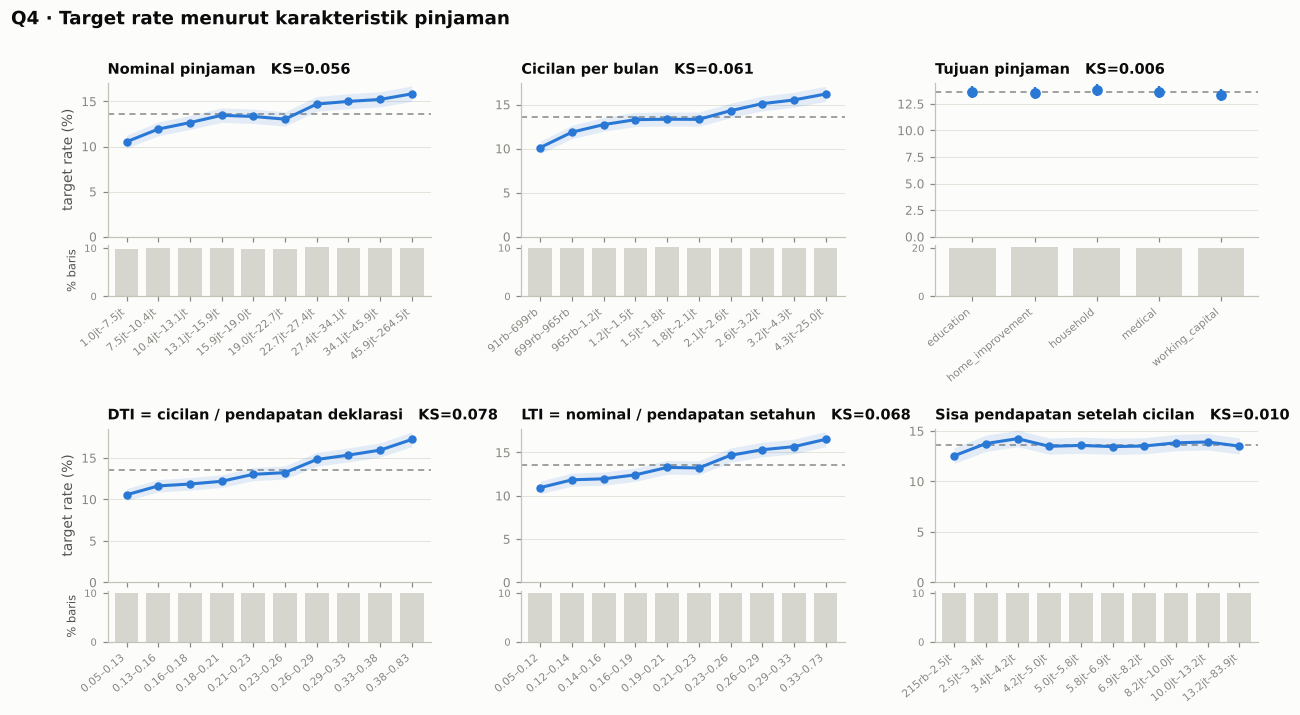

In [7]:
E.plot_rates(df, ["loan_amount", "proposed_monthly_installment", "loan_purpose", "dti", "lti", "residual_income"],
             titles={"loan_amount": "Nominal pinjaman", "proposed_monthly_installment": "Cicilan per bulan",
                     "loan_purpose": "Tujuan pinjaman", "dti": "DTI = cicilan / pendapatan deklarasi",
                     "lti": "LTI = nominal / pendapatan setahun", "residual_income": "Sisa pendapatan setelah cicilan"},
             suptitle="Q4 · Target rate menurut karakteristik pinjaman")

**Jawaban Q4.** Risiko naik **perlahan dan monoton** seiring besarnya beban pinjaman:
- Default rate naik dari 10,6% (DTI terendah) menjadi 17,2% (DTI tertinggi). Pola serupa terlihat untuk LTI, nominal, dan cicilan.
- **Tujuan pinjaman tidak berpengaruh** (13,3–13,8%) dan bisa dibuang.
- Sisa pendapatan dalam rupiah absolut (`residual_income`) justru hampir datar. Yang penting adalah **rasio beban terhadap pendapatan**, bukan nominal rupiahnya.

**Implikasi fitur**: pakai versi rasio (DTI, LTI). Nanti, saat data biro tersedia, tambahkan **total beban utang** (cicilan baru + utang yang sudah ada), bukan hanya pinjaman ini.

## Q5 · Profil nasabah

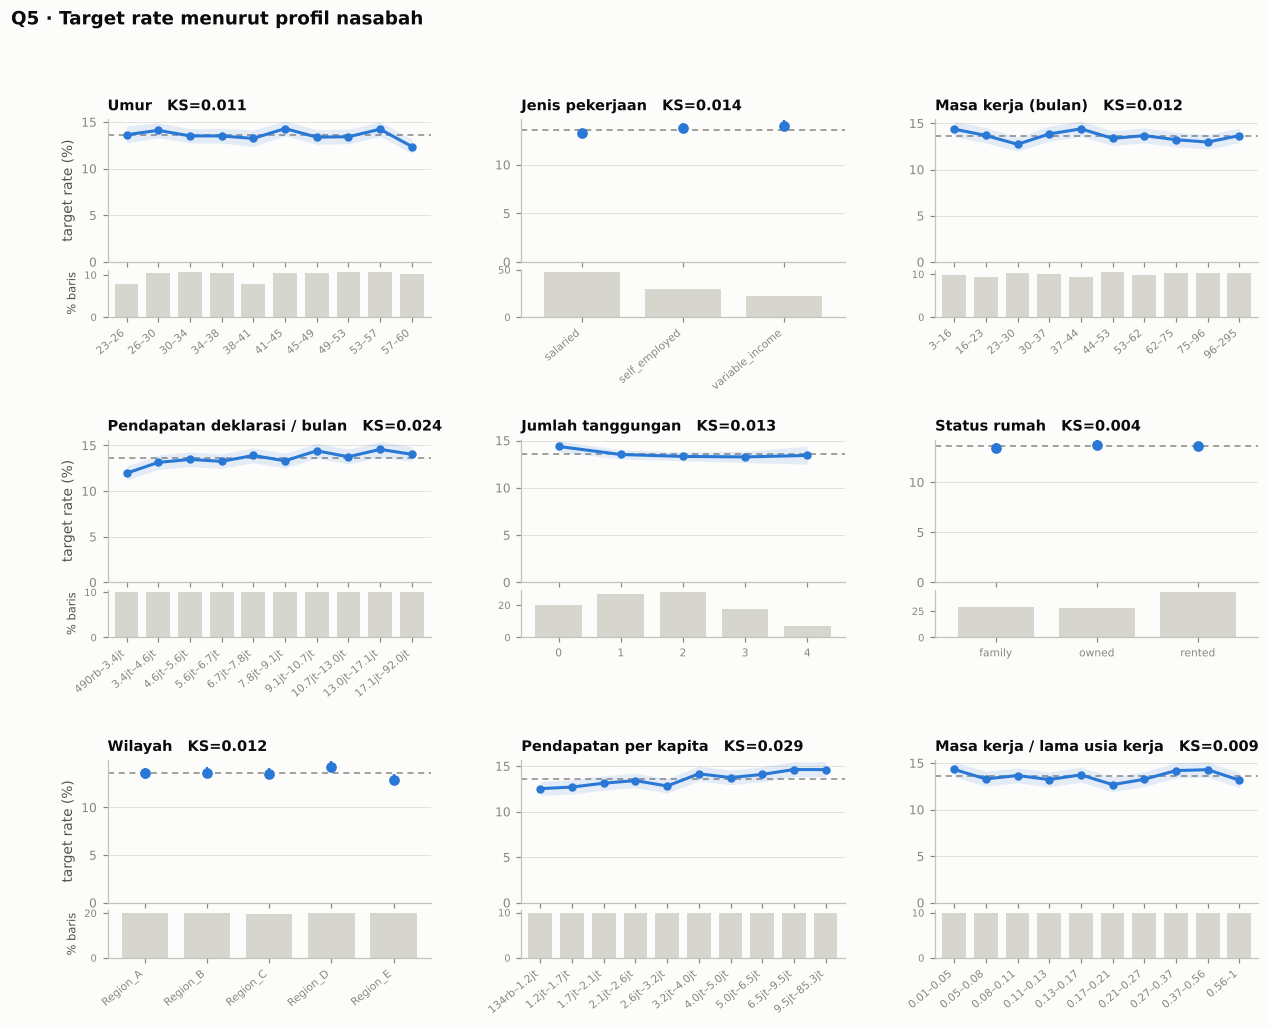

In [8]:
E.plot_rates(df, ["age", "employment_type", "employment_tenure_months", "declared_monthly_income",
                  "dependents", "housing_status", "region", "income_per_capita", "tenure_share_of_career"],
             titles={"age": "Umur", "employment_type": "Jenis pekerjaan", "employment_tenure_months": "Masa kerja (bulan)",
                     "declared_monthly_income": "Pendapatan deklarasi / bulan", "dependents": "Jumlah tanggungan",
                     "housing_status": "Status rumah", "region": "Wilayah", "income_per_capita": "Pendapatan per kapita",
                     "tenure_share_of_career": "Masa kerja / lama usia kerja"},
             suptitle="Q5 · Target rate menurut profil nasabah")

**Jawaban Q5 — profil demografi hampir tidak informatif.**
Semua kurva datar di sekitar 13–14%, dengan pita interval kepercayaan yang menyentuh garis rata-rata. Ada beberapa "gerigi", misalnya umur 57–60 tahun 12,4% atau Region_D 14,3% vs Region_E 12,9%, tapi bentuknya tidak monoton dan tidak masuk akal secara bisnis. Itu ciri khas noise.

Satu-satunya yang konsisten (tapi kecil) adalah **pendapatan**: semakin tinggi pendapatan deklarasi atau pendapatan per kapita, risikonya justru **sedikit naik**. Ini berlawanan dengan intuisi, dan kemungkinan karena nasabah berpendapatan tinggi mengambil pinjaman yang juga lebih besar.

**Implikasi**: kolom profil tetap boleh masuk model (biayanya kecil), tapi **jangan berharap banyak** dan jangan menghabiskan waktu merekayasa fitur dari profil saja. Nilainya lebih sebagai **penyebut** untuk rasio (pendapatan → DTI, tanggungan → per kapita).

## Q6 · Apakah pendapatan deklarasi bisa dipercaya?

Hipotesis dari diskusi awal: DTI lemah karena pendapatan deklarasi "dikarang". Kita uji pada 70% nasabah yang punya data rekening, dengan membandingkan pendapatan deklarasi vs rata-rata `income_like_credits` 6 bulan terakhir sebelum keputusan.

49,000 nasabah dengan rekening | korelasi Spearman deklarasi vs riil: 0.792
Rasio deklarasi / riil (kuantil 5-25-50-75-95%): [0.94, 1.31, 1.68, 2.21, 3.53]


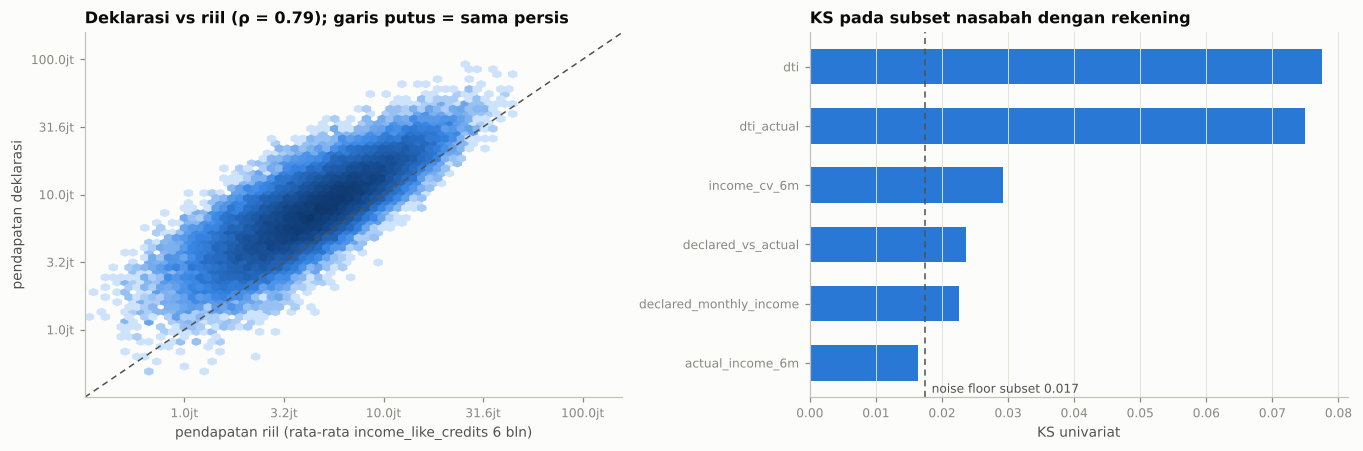

Noise floor subset rekening: 0.0174  (full train: 0.0144)


feature,type,null_pct,n_unique,ks,auc,arah,iv,ks_x_noise_subset
str,str,f64,i64,f64,f64,str,f64,f64
"""dti""","""num""",0.0,49000,0.0775,0.5491,"""↑ nilai → ↑ risiko""",0.0297,4.4
"""dti_actual""","""num""",0.0,49000,0.075,0.5484,"""↑ nilai → ↑ risiko""",0.0298,4.3
"""income_cv_6m""","""num""",0.0,49000,0.0292,0.5165,"""↑ nilai → ↑ risiko""",0.0042,1.7
"""declared_vs_actual""","""num""",0.0,49000,0.0236,0.5121,"""↑ nilai → ↑ risiko""",0.0028,1.4
"""declared_monthly_income""","""num""",0.0,48940,0.0226,0.5156,"""↑ nilai → ↑ risiko""",0.0043,1.3
"""actual_income_6m""","""num""",0.0,48978,0.0164,0.5083,"""↑ nilai → ↑ risiko""",0.0016,0.9


In [9]:
ab = E.load("account_behavior", ["customer_id", "month", "income_like_credits", "inflows"])
inc = (ab.sort("customer_id", "month")
         .group_by("customer_id")
         .agg(actual_income_6m=pl.col("income_like_credits").tail(6).mean(),
              income_cv_6m=pl.col("income_like_credits").tail(6).std() / pl.col("income_like_credits").tail(6).mean()))
d6 = (df.join(inc, on="customer_id", how="inner")
        .with_columns(declared_vs_actual=pl.col("declared_monthly_income") / pl.col("actual_income_6m"),
                      dti_actual=pl.col("proposed_monthly_installment") / pl.col("actual_income_6m")))
rho = d6.select(pl.corr("declared_monthly_income", "actual_income_6m", method="spearman")).item()
print(f"{d6.height:,} nasabah dengan rekening | korelasi Spearman deklarasi vs riil: {rho:.3f}")
print("Rasio deklarasi / riil (kuantil 5-25-50-75-95%):",
      [round(d6["declared_vs_actual"].quantile(q), 2) for q in (0.05, 0.25, 0.5, 0.75, 0.95)])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
hb = ax.hexbin(np.log10(d6["actual_income_6m"]), np.log10(d6["declared_monthly_income"]), gridsize=55,
               cmap=E.SEQ_CMAP, mincnt=1, bins="log")
lims = [5.5, 8.2]
ax.plot(lims, lims, color=E.INK2, lw=1, ls=(0, (4, 3)))
ax.set_xlim(lims); ax.set_ylim(lims)
ticks = [6, 6.5, 7, 7.5, 8]
ax.set_xticks(ticks); ax.set_xticklabels([E.fmt_num(10**t) for t in ticks])
ax.set_yticks(ticks); ax.set_yticklabels([E.fmt_num(10**t) for t in ticks])
ax.set_xlabel("pendapatan riil (rata-rata income_like_credits 6 bln)")
ax.set_ylabel("pendapatan deklarasi")
ax.set_title(f"Deklarasi vs riil (ρ = {rho:.2f}); garis putus = sama persis")
ax.grid(False)
sig6 = E.signal_table(d6, ["dti", "dti_actual", "declared_vs_actual", "declared_monthly_income", "actual_income_6m", "income_cv_6m"])
s = sig6.sort("ks")
axes[1].barh(s["feature"].to_list(), s["ks"].to_list(), color=E.C_RATE, height=0.6)
# noise floor HARUS dihitung ulang untuk subset ini (49k baris, ~7k positif) → lebih tinggi dari 0,0144
NOISE6 = E.ks_noise_floor(d6["target"].to_numpy(), n_perm=200, q=0.95)
axes[1].axvline(NOISE6, color=E.INK2, lw=1, ls=(0, (4, 3)))
axes[1].text(NOISE6 + 0.001, -0.45, f"noise floor subset {NOISE6:.3f}", fontsize=8, color=E.INK2, va="center")
axes[1].grid(axis="x"); axes[1].grid(axis="y", visible=False)
axes[1].set_title("KS pada subset nasabah dengan rekening"); axes[1].set_xlabel("KS univariat")
plt.tight_layout(); plt.show()
print(f"Noise floor subset rekening: {NOISE6:.4f}  (full train: {NOISE:.4f})")
sig6.with_columns((pl.col("ks") / NOISE6).round(1).alias("ks_x_noise_subset"))

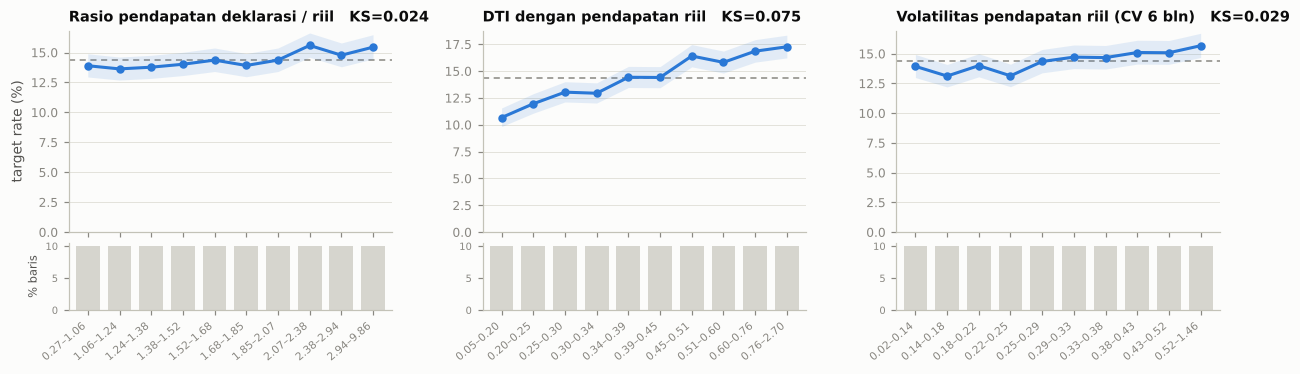

In [10]:
E.plot_rates(d6, ["declared_vs_actual", "dti_actual", "income_cv_6m"], ncols=3,
             titles={"declared_vs_actual": "Rasio pendapatan deklarasi / riil", "dti_actual": "DTI dengan pendapatan riil",
                     "income_cv_6m": "Volatilitas pendapatan riil (CV 6 bln)"})

**Jawaban Q6 — hipotesis "pendapatan dikarang" ditolak.**
- Pendapatan deklarasi **berkorelasi kuat** dengan pendapatan riil (ρ ≈ 0,79). Nilainya rata-rata ~1,7× `income_like_credits`, tapi kelipatan ini hampir sama untuk semua jenis pekerjaan. Kemungkinan `income_like_credits` memang tidak menangkap seluruh pendapatan, bukan karena nasabah berbohong.
- DTI dengan pendapatan riil (KS 0,075) **tidak lebih baik** daripada DTI deklarasi (0,078).
- Subset ini lebih kecil (49k baris), jadi noise floor-nya juga lebih tinggi, **≈ 0,017** (bukan 0,0144). Diukur dengan patokan ini, rasio deklarasi/riil (1,4×) dan pendapatan deklarasi (1,3×) masih tergolong **noise**. Grafiknya memang menunjukkan nasabah yang melebih-lebihkan pendapatan ≥2× sedikit lebih berisiko (~15% vs ~14%), tapi bedanya terlalu kecil untuk dipercaya.
- Yang sedikit lebih menjanjikan adalah **volatilitas pendapatan riil** (`income_cv_6m`, KS 0,029 ≈ 1,7× noise, tipis). Bagian 4 akan menggali dimensi arus kas ini lebih dalam.

**Kesimpulan**: DTI lemah bukan karena datanya kotor. Di dataset ini, **beban pinjaman memang hanya prediktor sekunder**.

## Q7 · Setelah suku bunga diketahui, apakah fitur lain masih menambah informasi?

Ini pertanyaan kunci. Model akan selalu punya suku bunga, jadi fitur hanya berguna kalau membawa informasi **di luar** suku bunga. Dua cara mengujinya:
1. **KS di dalam tiap kelompok suku bunga** dibanding noise floor kelompok itu. Kalau `excess_within` ≤ 0, sinyal fitur sudah sepenuhnya tercakup oleh bunga.
2. **Observed / Expected (O/E)**: expected = target rate kelompok bunganya. Kalau O/E ≈ 1 di semua bin, fitur tidak menambah apa-apa.

In [11]:
df = df.with_columns(expected_by_rate=pl.col("target").mean().over("annual_interest_rate"))
rows = []
for f in ["dti", "lti", "loan_amount", "has_history", "declared_monthly_income", "income_per_capita",
          "age", "employment_type", "employment_tenure_months", "dependents", "housing_status", "region"]:
    summ, _ = E.ks_within(df, f, "annual_interest_rate", n_perm=30)
    rows.append(summ)
within = (pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))
            .with_columns(pl.when(pl.col("excess_within") > 0.005).then(pl.lit("✅ ada info tambahan"))
                            .otherwise(pl.lit("— sudah tercakup bunga / noise")).alias("verdict"))
            .sort("excess_within", descending=True))
within

feature,ks_overall,ks_within,noise_within,excess_within,verdict
str,f64,f64,f64,f64,str
"""dti""",0.0778,0.0489,0.0312,0.0178,"""✅ ada info tambahan"""
"""lti""",0.0684,0.0489,0.0312,0.0178,"""✅ ada info tambahan"""
"""loan_amount""",0.0556,0.0473,0.0312,0.0161,"""✅ ada info tambahan"""
"""income_per_capita""",0.0288,0.0385,0.0312,0.0074,"""✅ ada info tambahan"""
"""has_history""",0.0476,0.0331,0.0312,0.002,"""— sudah tercakup bunga / noise"""
"""declared_monthly_income""",0.0236,0.033,0.0312,0.0019,"""— sudah tercakup bunga / noise"""
"""employment_tenure_months""",0.0124,0.0258,0.0312,-0.0054,"""— sudah tercakup bunga / noise"""
"""region""",0.0123,0.0237,0.0312,-0.0075,"""— sudah tercakup bunga / noise"""
"""housing_status""",0.0037,0.0212,0.0312,-0.0099,"""— sudah tercakup bunga / noise"""


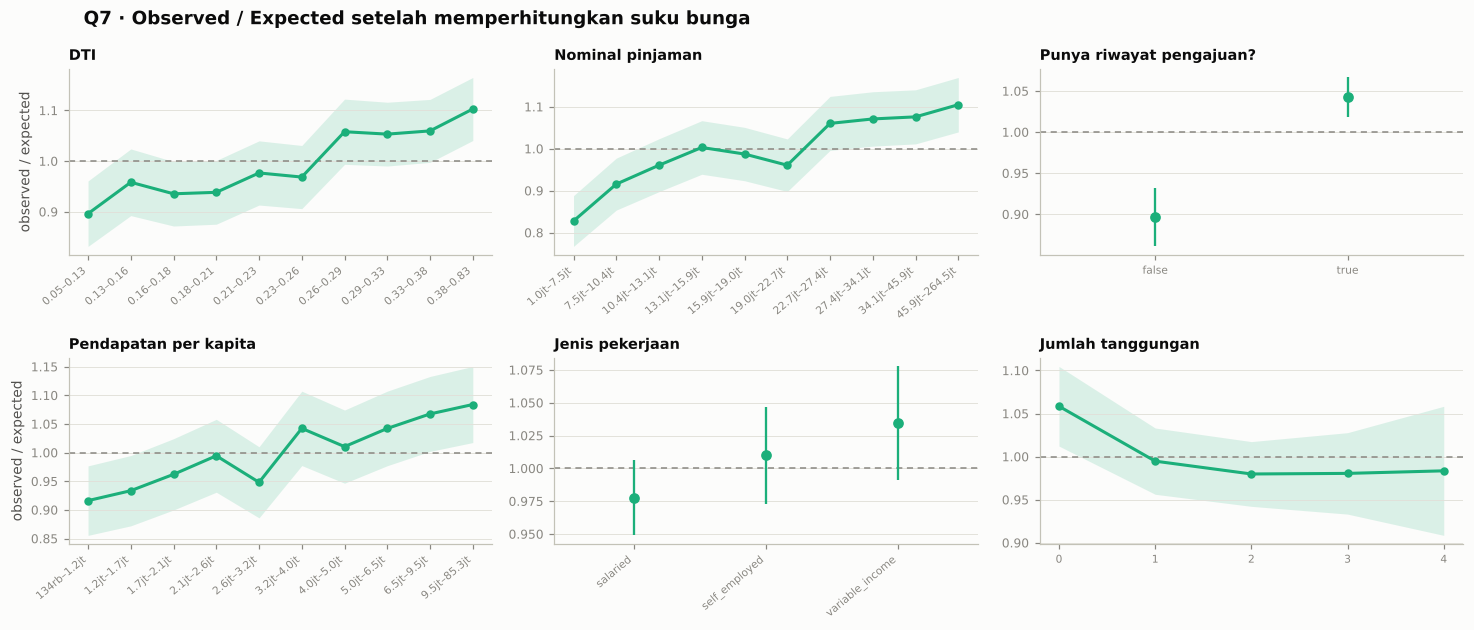

In [12]:
E.plot_oe(df, ["dti", "loan_amount", "has_history", "income_per_capita", "employment_type", "dependents"],
          expected="expected_by_rate",
          titles={"dti": "DTI", "loan_amount": "Nominal pinjaman", "has_history": "Punya riwayat pengajuan?",
                  "income_per_capita": "Pendapatan per kapita", "employment_type": "Jenis pekerjaan",
                  "dependents": "Jumlah tanggungan"},
          suptitle="Q7 · Observed / Expected setelah memperhitungkan suku bunga")

**Jawaban Q7.** Hanya sedikit fitur yang masih membawa info di luar suku bunga, dan efeknya **kecil**:
- **Beban pinjaman (`dti`, `lti`, `loan_amount`)**: KS di dalam kelompok bunga masih ~0,018 di atas noise, dan O/E bergerak dari ~0,85–0,90 (beban ringan) ke ~1,10 (beban berat). Lender tampaknya belum memperhitungkan besarnya pinjaman secara penuh saat menentukan bunga.
- **`has_history`**: KS-nya kecil karena fitur biner hanya punya satu titik potong, tapi O/E-nya jelas berbeda. Nasabah lama **1,04×** dari ekspektasi, nasabah baru **0,90×**, dan interval kepercayaannya tidak tumpang-tindih. Ini petunjuk bahwa **riwayat internal menyimpan sinyal yang belum sepenuhnya tercermin di bunga** (topik Bagian 2).
- **`income_per_capita`**: ada pola yang berlawanan dengan intuisi. Setelah bunga diperhitungkan, pendapatan per kapita yang **lebih tinggi** justru sedikit **lebih berisiko** (O/E 0,92 → 1,08), dan nasabah tanpa tanggungan juga sedikit lebih berisiko. Efeknya kecil; tetap masukkan ke model dan biarkan model yang menilai.
- Fitur demografi lain: `excess_within` ≤ 0, jadi **tidak ada info tambahan**.

## Q8 · Nasabah baru vs nasabah lama

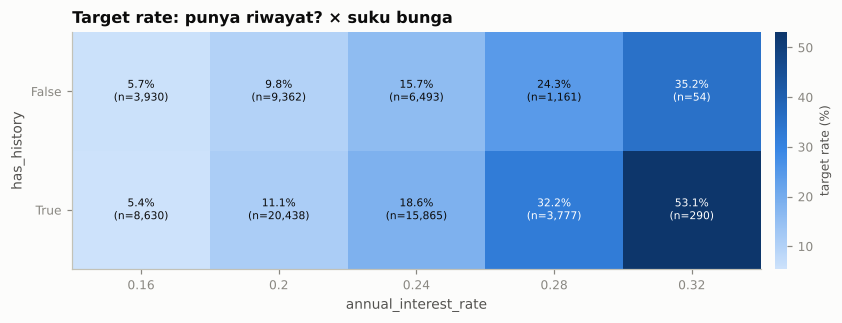

has_history,n,target_rate,mean_rate,pct_rate_ge_28,median_income,mean_age,median_loan,median_dti,pct_salaried
bool,u32,f64,f64,f64,f64,f64,f64,f64,f64
true,49000,0.144,0.213,8.3,7.801164e6,41.469,1.9e7,0.234,47.735
false,21000,0.117,0.21,5.786,7.746147e6,41.446,1.89e7,0.234,48.014


In [13]:
E.heatmap_rate(df, "has_history", "annual_interest_rate", title="Target rate: punya riwayat? × suku bunga", figsize=(8.5, 2.8))
(df.group_by("has_history")
   .agg(n=pl.len(), target_rate=pl.col("target").mean(), mean_rate=pl.col("annual_interest_rate").mean(),
        pct_rate_ge_28=(pl.col("annual_interest_rate") >= 0.28).mean() * 100,
        median_income=pl.col("declared_monthly_income").median(), mean_age=pl.col("age").mean(),
        median_loan=pl.col("loan_amount").median(), median_dti=pl.col("dti").median(),
        pct_salaried=(pl.col("employment_type") == "salaried").mean() * 100)
   .with_columns(pl.col(pl.Float64).round(3)))

**Jawaban Q8.** Dua kelompok ini **profilnya identik** (umur, pendapatan, pekerjaan, nominal), tapi:
- Nasabah lama lebih sering mendapat bunga tinggi (≥28%), dan default rate keseluruhannya lebih tinggi (14,4% vs 11,7%).
- Pada bunga yang sama, gap-nya makin lebar di bunga tinggi: di 28%, nasabah lama 32,2% vs nasabah baru 24,3%.

Interpretasi yang paling masuk akal: di dalam kelompok nasabah lama ada subkelompok yang **riwayatnya buruk** (pernah menunggak, ditolak, dll.), dan merekalah yang mendorong angka ini. Nasabah baru tidak punya "catatan merah" semacam itu.

**Implikasi pemodelan**:
1. Fitur riwayat (Bagian 2) kemungkinan besar adalah sumber sinyal terbesar kedua setelah bunga, atau bahkan yang terbesar.
2. Untuk 30% nasabah baru, semua fitur riwayat akan null. Model GBDT bisa menangani ini secara alami, tapi tetap sertakan **flag eksplisit** `has_history` dan pertimbangkan mengevaluasi KS per segmen.

## Q9 · Patokan: berapa KS dari aplikasi + profil saja?

LightGBM 5-fold stratified, prediksi out-of-fold. Ini **bukan model final**, hanya patokan agar setiap bagian EDA berikutnya bisa diukur kontribusinya.

In [14]:
CATS = ["loan_purpose", "region", "employment_type", "housing_status"]
APP_PROFILE = ["annual_interest_rate", "loan_amount", "proposed_monthly_installment", "loan_purpose",
               "age", "region", "employment_type", "employment_tenure_months", "declared_monthly_income",
               "dependents", "housing_status", "dti", "lti", "income_per_capita"]
configs = {
    "A. suku bunga saja": ["annual_interest_rate"],
    "B. aplikasi + profil (tanpa suku bunga)": [c for c in APP_PROFILE if c != "annual_interest_rate"],
    "C. aplikasi + profil (lengkap)": APP_PROFILE,
    "D. C + has_history": APP_PROFILE + ["has_history"],
}
res, imps = [], {}
for name, feats in configs.items():
    _, ks, auc, imp = E.cv_lgb(df, feats, cat_features=[c for c in CATS if c in feats])
    res.append(dict(config=name, n_features=len(feats), ks_oof=round(ks, 4), auc_oof=round(auc, 4)))
    imps[name] = imp
pl.DataFrame(res)

config,n_features,ks_oof,auc_oof
str,i64,f64,f64
"""A. suku bunga saja""",1,0.2301,0.6447
"""B. aplikasi + profil (tanpa suku bunga)""",13,0.1663,0.6143
"""C. aplikasi + profil (lengkap)""",14,0.2321,0.6435
"""D. C + has_history""",15,0.2281,0.6504


In [15]:
imps["D. C + has_history"].with_columns(pl.col("gain_pct").round(2))

feature,gain_pct
str,f64
"""annual_interest_rate""",69.83
"""dti""",3.82
"""employment_tenure_months""",3.73
"""income_per_capita""",3.62
"""loan_amount""",3.48
"""declared_monthly_income""",2.8
"""lti""",2.72
"""age""",2.26
"""proposed_monthly_installment""",2.08


**Jawaban Q9.**
- **Suku bunga saja → KS ≈ 0,23**, dan menambah seluruh kolom aplikasi + profil **tidak menaikkan KS**. Model GBDT pun mengonfirmasi bahwa profil tidak menambah informasi di luar bunga.
- Tanpa kolom bunga, model tetap mencapai KS ≈ 0,17, karena bunga "bocor" lewat kombinasi nominal + cicilan (lihat Q3).
- Selisih antara konfigurasi A, C, dan D (±0,004) **lebih kecil dari noise KS** (SD ~0,005 untuk 70k baris). Menambah `has_history` sedikit menaikkan AUC (0,644 → 0,650), tapi tidak KS.
- Importance gain didominasi suku bunga (~70%). Sisanya tersebar tipis di fitur yang hampir tidak berguna.

➡️ **Patokan untuk bagian berikutnya: KS ≈ 0,23.** Setiap sumber data baru akan dinilai dari seberapa jauh ia mendorong angka ini naik.

## Ringkasan Bagian 1

| Temuan | Implikasi untuk feature engineering |
|---|---|
| Suku bunga = sinyal terkuat (KS 0,23), monoton tajam 5% → 50% | Wajib masuk. Bisa juga dipakai sebagai numerik ordinal. |
| Cicilan / nominal membocorkan bunga 100% | Jangan anggap DTI/cicilan sebagai sinyal "independen"; importance-nya sebagian milik bunga. |
| Profil demografi ≈ noise, termasuk setelah dikondisikan pada bunga | Boleh masuk model, tapi jangan merekayasa fitur dari profil saja. Gunakan sebagai penyebut rasio. |
| Fitur waktu ≈ noise | **Buang** dari model. Waktu hanya dipakai sebagai titik acuan perhitungan fitur riwayat. |
| `loan_purpose` ≈ noise | Buang, atau biarkan (dampaknya kecil). |
| DTI/LTI sinyal sekunder (KS ~0,07), sedikit info di luar bunga | Pertahankan; nanti perluas menjadi **total beban utang** dengan data biro & pinjaman berjalan. |
| Pendapatan deklarasi konsisten dengan pendapatan riil (ρ 0,79) | Tidak perlu "koreksi" pendapatan; volatilitas pendapatan riil lebih menjanjikan (Bagian 4). |
| Nasabah lama lebih berisiko pada bunga yang sama | Sinyal besar kemungkinan ada di **riwayat internal** → fokus Bagian 2. |

**Yang dibawa ke bagian berikutnya**: patokan KS **0,23**; pertanyaan terbuka **"apa yang menentukan suku bunga?"** (Bagian 2 & 3); dan **pemisahan segmen nasabah baru vs lama**.